In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('../train.csv')

In [4]:
new_df = df.sample(30000,random_state=2)

In [5]:
def preprocess(q):
    q = str(q).lower().strip()
    
    # Replace certain special characters with their string equivalents:
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')


    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')

    # Replacing some numbers with string equivalents (not perfect, can be done better to account for more cases)
    q = q.replace(',000,000,000 ', 'b ')
    q = q.replace(',000,000 ', 'm ')
    q = q.replace(',000 ', 'k ')
    q = re.sub(r'([0-9]+)000000000', r'\1b', q)
    q = re.sub(r'([0-9]+)000000', r'\1m', q)
    q = re.sub(r'([0-9]+)000', r'\1k', q)

    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }


    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word]

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()

   # remove all kinds of whitespace
    q = re.sub(r'\s+', ' ', q).strip()
    
    return q

In [6]:
# apply the preprocess function on dataset 

new_df['question1'] = new_df['question1'].apply(preprocess)
new_df['question2'] = new_df['question2'].apply(preprocess)

In [7]:
# Create a new columns 'q1_len', q2_len char lenth of q1 and q2

new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [8]:
# create a new column of 'q1_num_words'  words in q1

new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9


In [9]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [10]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3


In [11]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [12]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13


In [13]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26,0.46
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22,0.32
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36,0.08
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32,0.00
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13,0.23


# Advanced Features

In [14]:
import nltk

# nltk.download('stopwords')

In [15]:
import nltk
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(stop_words)

{"should've", 'they', "we'd", 'weren', "she'll", 'more', 'myself', 'himself', 'up', "i've", 'mustn', 'which', 'where', 'you', 'wasn', "haven't", 'because', "couldn't", 'this', "mustn't", "aren't", 'after', 'hasn', 'other', 'very', 'doesn', "doesn't", "i'll", "he'd", 'having', 'down', "they'll", 'below', 'between', "he'll", 'she', 'there', 'i', 'who', 'has', 'few', 'it', "you'd", 'hers', 'ourselves', 'your', 'an', 'was', 'until', 'mightn', 'nor', 'into', 'a', 'all', "we've", 'whom', 'have', "you're", 'shan', 'above', 'no', 'then', 'd', 'most', 'these', 'haven', "wasn't", 'the', 'theirs', 'what', 'while', 'being', 'couldn', 'or', "it'd", 'aren', 'out', 'should', 'o', 'hadn', 'our', 'here', 'needn', "you'll", 'yourself', 'same', 'not', 'won', 'be', 'yours', "isn't", "they'd", 'y', "you've", 'just', 'how', 'did', 'herself', 'her', 'on', 'over', 'with', 'is', 'my', "they've", 'before', 'only', 'why', 'each', "needn't", "we'll", 'didn', 'his', 'themselves', 'as', "shouldn't", 't', "she's", '

In [16]:
# Advanced Features
from nltk.corpus import stopwords

def fetch_token_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return token_features

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])

    # get the stopwords in questions:
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])

    # Get the common non-stopwords from question pair
    common_word_count = len(q1_words.intersection(q2_words))

    # Get the common stopwords from question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))

    # Get the common tokens from question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))


    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)

    # Last word of both question is same or not
    token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])

    # First word of both question is same or not
    token_features[7] = int(q1_tokens[0] == q2_tokens[0])

    return token_features
    

In [17]:
token_features = new_df.apply(fetch_token_features, axis = 1)

In [18]:
new_df['cwc_min'] = list(map(lambda x: x[0], token_features))
new_df['cwc_max'] = list(map(lambda x: x[1], token_features))
new_df['csc_min'] = list(map(lambda x: x[2], token_features))
new_df['csc_max'] = list(map(lambda x: x[3], token_features))
new_df['ctc_min'] = list(map(lambda x: x[4], token_features))
new_df['ctc_max'] = list(map(lambda x: x[5], token_features))
new_df['last_word_eq'] = list(map(lambda x: x[6], token_features))
new_df['first_word_eq'] = list(map(lambda x: x[7], token_features))

# Length Based Features

In [19]:
# Length Based Features
import distance

def fetch_length_features(row):
    q1 = row['question1']
    q2 = row['question2']

    length_features = [0.0]*3

    # Converting the sentance into tokens:
    q1_tokens = q1.split()
    q2_tokens = q2.split()

    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return length_features

    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))

    # Average Token Length of both Questions   
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2

    strs = list(distance.lcsubstrings(q1, q2))
    length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)

    return length_features


In [20]:
length_features = new_df.apply(fetch_length_features, axis=1)

new_df['abs_len_diff'] = list(map(lambda x: x[0], length_features))
new_df['mean_len'] = list(map(lambda x: x[1], length_features))
new_df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

# Fuzzy Features

In [21]:
# Fuzzy Features

from fuzzywuzzy import fuzz

def fetch_fuzzy_features(row):
    q1 = row['question1']
    q2 = row['question2']

    fuzzy_features = [0.0]*4

    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)  # Usage: This provides a similarity score by performing an exact character-by-character comparison of the two strings (case-sensitive).

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)   # Use: Yeh substring matching ke liye hota hai. Agar ek string choti hai aur wo badi string ke andar kahi bhi milti hai, toh yeh high score deta hai.


 # Use: Yeh words ko alphabetical order mein sort karke compare karta hai. Isse farq nahi padta ki words aage-piche likhe hain ya nahi (jaise "machine learning" aur "learning machine").
    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)   


# Usage: It ignores duplicate words and matches overlapping words without regard to order.
    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)  


    return fuzzy_features


In [22]:
fuzzy_features = new_df.apply(fetch_fuzzy_features, axis=1)

# Creating new feature columns for fuzzy features
new_df['fuzz_ratio'] = list(map(lambda x: x[0], fuzzy_features))
new_df['fuzz_partial_ratio'] = list(map(lambda x: x[1], fuzzy_features))
new_df['token_sort_ratio'] = list(map(lambda x: x[2], fuzzy_features))
new_df['token_set_ratio'] = list(map(lambda x: x[3], fuzzy_features))

In [23]:
new_df.shape

(30000, 28)

In [24]:
new_df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common',
       'word_total', 'word_share', 'cwc_min', 'cwc_max', 'csc_min', 'csc_max',
       'ctc_min', 'ctc_max', 'last_word_eq', 'first_word_eq', 'abs_len_diff',
       'mean_len', 'longest_substr_ratio', 'fuzz_ratio', 'fuzz_partial_ratio',
       'token_sort_ratio', 'token_set_ratio'],
      dtype='str')

# Perform EDA on new columns 

In [25]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...
151235,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy


In [26]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [27]:
final_df.columns

Index(['is_duplicate', 'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words',
       'word_common', 'word_total', 'word_share', 'cwc_min', 'cwc_max',
       'csc_min', 'csc_max', 'ctc_min', 'ctc_max', 'last_word_eq',
       'first_word_eq', 'abs_len_diff', 'mean_len', 'longest_substr_ratio',
       'fuzz_ratio', 'fuzz_partial_ratio', 'token_sort_ratio',
       'token_set_ratio'],
      dtype='str')

In [28]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [29]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 6000)

In [30]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 6023)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0,0,0,0,0,0,0,0,0,0
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0,0,0,0,0,0,0,0,0,0
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0,0,0,0,0,0,0,0,0,0
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0,0,0,1,0,0,0,0,0,0
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0,0,0,0,0,0,0,0,0,0


In [31]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [32]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2', C=0.1, solver='saga',max_iter=200, class_weight='balanced')
lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadde

In [33]:
y_pred = lr.predict(X_test)

In [34]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.6773333333333333

In [35]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6773333333333333

Confusion Matrix:
[[2395 1417]
 [ 519 1669]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.63      0.71      3812
           1       0.54      0.76      0.63      2188

    accuracy                           0.68      6000
   macro avg       0.68      0.70      0.67      6000
weighted avg       0.72      0.68      0.68      6000



In [36]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 3. Initialize the model
model = GaussianNB()

# 4. Train (fit) the model
model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.60

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.49      0.61      3812
           1       0.47      0.78      0.59      2188

    accuracy                           0.60      6000
   macro avg       0.63      0.64      0.60      6000
weighted avg       0.68      0.60      0.60      6000



# StandardScaler

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)


# model = LogisticRegression(max_iter=1000)
model = LogisticRegression(penalty='l2', C=0.1, solver='saga',max_iter=200, class_weight='balanced')
model.fit(X_train_sc, y_train)

y_pred = model.predict(X_test_sc)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=['not_duplicate', 'duplicate']))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.7376666666666667

Classification Report:
                precision    recall  f1-score   support

not_duplicate       0.82      0.75      0.78      3812
    duplicate       0.62      0.71      0.66      2188

     accuracy                           0.74      6000
    macro avg       0.72      0.73      0.72      6000
 weighted avg       0.75      0.74      0.74      6000


Confusion Matrix:
 [[2867  945]
 [ 629 1559]]


In [38]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 3. Initialize the model
model = GaussianNB()

# 4. Train (fit) the model
model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.60

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.49      0.61      3812
           1       0.47      0.78      0.59      2188

    accuracy                           0.60      6000
   macro avg       0.63      0.64      0.60      6000
weighted avg       0.68      0.60      0.60      6000



# SGDClassifier

In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [40]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [41]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
model = SGDClassifier(penalty ='l2', eta0=0.01, loss='log_loss', max_iter=5, random_state=42)

# Train
model.fit(X_train_sc, y_train)
y_pred = model.predict(X_test_sc)

from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.7316666666666667

In [42]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 3. Initialize the model
model = GaussianNB()

# 4. Train (fit) the model
model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.60

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.49      0.61      3812
           1       0.47      0.78      0.59      2188

    accuracy                           0.60      6000
   macro avg       0.63      0.64      0.60      6000
weighted avg       0.68      0.60      0.60      6000



# word2Vex 

In [72]:
new_df_1 = new_df
new_df_1.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74


In [73]:
ques_df = new_df_1[['question1','question2']]
ques_df.head(4)

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...


In [74]:
final_df_1 = new_df_1.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df_1.shape)
final_df_1.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [75]:
import numpy as np
from gensim.models import Word2Vec

# Select questions
ques_df = new_df[['question1', 'question2']].copy()


# 1. Tokenization

questions = list(ques_df['question1']) + list(ques_df['question2'])

tokenized_questions = [question.lower().split() for question in questions]

# 2. Train Word2Vec

w2v_model = Word2Vec(
    sentences=tokenized_questions,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# 3. Convert each question into a vector

def question_to_vector(question, model):

    words = question.lower().split()

    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)



# 4. Create vectors for all questions

question_vectors = np.array([question_to_vector(question, w2v_model) for question in questions])


# 5. Split Q1 and Q2

q1_arr, q2_arr = np.vsplit(question_vectors, 2)

print("Q1 shape:", q1_arr.shape)
print("Q2 shape:", q2_arr.shape)


Q1 shape: (30000, 100)
Q2 shape: (30000, 100)


In [76]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 200)

In [77]:
final_df_1 = pd.concat([final_df_1, temp_df], axis=1)
print(final_df_1.shape)
final_df_1.head()

(30000, 223)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,90,91,92,93,94,95,96,97,98,99
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.235040,0.135927,0.070378,0.093272,0.299519,0.120928,0.050769,-0.090867,0.002326,0.175318
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.100996,0.010994,0.061684,-0.113319,0.643737,0.023313,0.206837,0.032774,-0.170675,-0.014836
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.294407,0.084817,0.111772,-0.022581,0.516099,0.067829,0.142229,-0.074938,-0.075775,-0.072501
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.305855,0.016607,-0.096040,0.013499,0.514098,0.192170,0.244178,-0.117605,-0.266242,0.144954
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.350691,-0.049163,-0.046912,0.188474,0.246818,0.084501,-0.000345,-0.089021,-0.131831,0.240448


In [86]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df_1.iloc[:,1:].values,final_df_1.iloc[:,0].values,test_size=0.2,random_state=1)

In [87]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [51]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2', C=0.01, solver='saga',max_iter=200, class_weight='balanced')
lr.fit(X_train_sc, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.01
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadd

In [52]:
y_pred = lr.predict(X_test_sc)

In [53]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.7515

In [54]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
model = SGDClassifier(penalty ='l2', eta0=0.01, loss='log_loss', max_iter=200, random_state=42, learning_rate='adaptive', alpha = 0.0001 )

# Train
model.fit(X_train_sc, y_train)
y_pred = model.predict(X_test_sc)

from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)
print(y_pred)

[1 0 0 ... 1 0 0]


In [55]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=['not_duplicate', 'duplicate']))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))



Accuracy: 0.7586666666666667

Classification Report:
                precision    recall  f1-score   support

not_duplicate       0.79      0.84      0.82      3812
    duplicate       0.69      0.61      0.65      2188

     accuracy                           0.76      6000
    macro avg       0.74      0.73      0.73      6000
 weighted avg       0.75      0.76      0.76      6000


Confusion Matrix:
 [[3209  603]
 [ 845 1343]]


In [56]:
print(model.get_params())

{'alpha': 0.0001, 'average': False, 'class_weight': None, 'early_stopping': False, 'epsilon': 0.1, 'eta0': 0.01, 'fit_intercept': True, 'l1_ratio': 0.15, 'learning_rate': 'adaptive', 'loss': 'log_loss', 'max_iter': 200, 'n_iter_no_change': 5, 'n_jobs': None, 'penalty': 'l2', 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'tol': 0.001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [57]:
print(model.t_)

1032001.0


In [58]:
print(model.n_iter_)

43


In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

# Extract features and target from final_df_1
X = final_df_1.iloc[:, 1:].values
y = final_df_1.iloc[:, 0].values

# (Optional but recommended) scale features for Logistic Regression
X = StandardScaler().fit_transform(X)

clf = LogisticRegression(max_iter=1000)
scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
print("Logistic Regression CV accuracy:", scores.mean())

Logistic Regression CV accuracy: 0.7583666666666666


###  plot graph of epoch and Log loss 

Epoch 1: loss = 0.6044, accuracy = 0.7158
Epoch 2: loss = 0.6034, accuracy = 0.7153
Epoch 3: loss = 0.6023, accuracy = 0.7156
Epoch 4: loss = 0.6013, accuracy = 0.7154
Epoch 5: loss = 0.6006, accuracy = 0.7159
Epoch 6: loss = 0.6000, accuracy = 0.7161
Epoch 7: loss = 0.5995, accuracy = 0.7163
Epoch 8: loss = 0.5991, accuracy = 0.7166
Epoch 9: loss = 0.5988, accuracy = 0.7167
Epoch 10: loss = 0.5985, accuracy = 0.7167
Epoch 11: loss = 0.5983, accuracy = 0.7168
Epoch 12: loss = 0.5982, accuracy = 0.7170
Epoch 13: loss = 0.5980, accuracy = 0.7171
Epoch 14: loss = 0.5979, accuracy = 0.7172
Epoch 15: loss = 0.5978, accuracy = 0.7173
Epoch 16: loss = 0.5977, accuracy = 0.7174
Epoch 17: loss = 0.5977, accuracy = 0.7174
Epoch 18: loss = 0.5976, accuracy = 0.7174
Epoch 19: loss = 0.5976, accuracy = 0.7173
Epoch 20: loss = 0.5975, accuracy = 0.7174
Epoch 21: loss = 0.5975, accuracy = 0.7175
Epoch 22: loss = 0.5975, accuracy = 0.7174
Epoch 23: loss = 0.5974, accuracy = 0.7174
Epoch 24: loss = 0.5

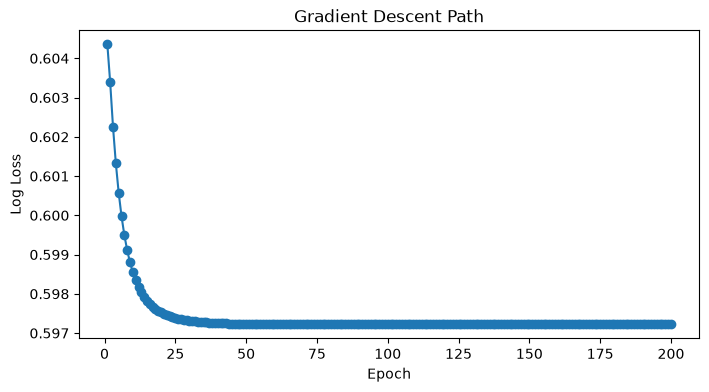

In [60]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import log_loss, accuracy_score

# -----------------------------------
# Create model
# -----------------------------------

model = SGDClassifier(
    penalty='l2',
    eta0=0.01,
    loss='log_loss',
    learning_rate='adaptive',
    alpha=0.0001,
    max_iter=1,
    tol=None,
    warm_start=True,
    random_state=42
)

# Store values
loss_val = []
accuracy_val = []
epoch = []

epochs = 200

# -----------------------------------
# Train one epoch at a time
# -----------------------------------

for i in range(epochs):

    model.fit(X_train_sc, y_train)

    # Get intercept (b)
    b = model.intercept_[0]

    # Predict probability
    y_prob = model.predict_proba(X_train_sc)[:, 1]

    # Calculate log loss
    loss = log_loss(y_train, y_prob)

    # Calculate accuracy
    y_pred = model.predict(X_train_sc)
    accuracy = accuracy_score(y_train, y_pred)

    # Store values

    loss_val.append(loss)
    accuracy_val.append(accuracy)
    epoch.append(i+1)

    print(
        f"Epoch {i+1}: "
        f"loss = {loss:.4f}, "
        f"accuracy = {accuracy:.4f}"
    )

    



plt.figure(figsize=(8, 4))

plt.plot(epoch, loss_val, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Log Loss")
plt.title("Gradient Descent Path")

plt.show()


# Naiv Bayes Model:

In [106]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df_1.iloc[:,1:].values,final_df_1.iloc[:,0].values,test_size=0.2,random_state=1)


In [107]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [150]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# 3. Initialize the model
model_g = GaussianNB(var_smoothing = 1e-9)

# 4. Train (fit) the model
model_g.fit(X_train_sc, y_train)

# 5. Make predictions
y_pred = model_g.predict(X_test_sc)

# 6. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("matrix \n", confusion_matrix(y_test, y_pred))

Accuracy: 0.71

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.69      0.75      3812
           1       0.58      0.72      0.64      2188

    accuracy                           0.71      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.73      0.71      0.71      6000

matrix 
 [[2648 1164]
 [ 604 1584]]


In [151]:
# check the Bias and Variance

# Training accuracy
y_train_pred = model.predict(X_train_sc)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = model.predict(X_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Accuracy Gap:", train_acc - test_acc)

Training Accuracy: 0.7045416666666666
Testing Accuracy: 0.703
Accuracy Gap: 0.0015416666666666634


In [114]:
model_g.get_params()

{'priors': None, 'var_smoothing': 1e-09}

In [148]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



# 3. Initialize the model
model_b = BernoulliNB(binarize = 0.4, alpha=1.0)

# 4. Train (fit) the model
model_b.fit(X_train_sc, y_train)

# 5. Make predictions
y_pred = model_b.predict(X_test_sc)

# 6. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("matrix \n", confusion_matrix(y_test, y_pred))

Accuracy: 0.70

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.66      0.74      3812
           1       0.57      0.77      0.65      2188

    accuracy                           0.70      6000
   macro avg       0.70      0.72      0.70      6000
weighted avg       0.74      0.70      0.71      6000

matrix 
 [[2529 1283]
 [ 500 1688]]


In [149]:
# check the Bias and Variance

# Training accuracy
y_train_pred = model_b.predict(X_train_sc)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = model_b.predict(X_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Accuracy Gap:", train_acc - test_acc)

Training Accuracy: 0.7043333333333334
Testing Accuracy: 0.7028333333333333
Accuracy Gap: 0.0015000000000000568


In [145]:
model_b.get_params()

{'alpha': 1.0,
 'binarize': 0.4,
 'class_prior': None,
 'fit_prior': True,
 'force_alpha': True}

In [63]:
l = model.feature_count_
l

array([[6593., 6155., 6079., 6158., 4832., 6951., 5701., 6312., 5682.,
        6698., 5673., 5954., 5270., 3226., 6644., 6276., 6841., 5164.,
        5708., 5782., 5652., 6307., 8180., 6969., 8209., 7982., 8076.,
        7915., 7010., 6702., 7617., 7924., 7513., 9004., 6951., 8249.,
        7629., 7901., 7027., 7503., 7823., 8529., 7166., 6756., 6927.,
        7867., 7392., 7264., 8310., 6895., 7536., 7626., 6876., 6733.,
        7125., 7707., 7675., 6572., 6990., 7609., 8119., 8119., 7547.,
        7886., 7814., 7222., 7003., 7389., 8461., 7808., 7368., 7053.,
        7691., 7339., 8064., 7896., 7591., 7883., 7989., 7986., 7195.,
        6967., 7838., 7747., 6862., 7616., 7723., 7009., 7213., 7567.,
        7615., 7048., 7668., 8300., 7589., 7157., 6990., 7591., 7864.,
        7733., 8099., 8437., 8501., 7082., 7319., 7096., 8574., 7783.,
        7289., 7595., 7470., 7557., 6698., 7943., 7418., 8314., 6323.,
        7913., 6951., 7560., 7345., 7486., 8200., 7013., 8081., 7839.,
      

In [104]:
X_train_sc.shape

(24000, 222)

In [65]:
model.class_count_

array([15201.,  8799.])

In [109]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# 1. Initialize the model (Scaler ki koi zaroorat nahi hai)
model = MultinomialNB()

# 2. Train (fit) the model directly on raw features
model.fit(X_train_sc, y_train)

# 3. Make predictions
y_pred = model.predict(X_test_sc)

# 4. Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.68

Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.78      0.76      3812
           1       0.57      0.52      0.54      2188

    accuracy                           0.68      6000
   macro avg       0.65      0.65      0.65      6000
weighted avg       0.68      0.68      0.68      6000



In [83]:
from sklearn.datasets import load_iris
import pandas as pd

# as_frame=True likhne se yeh seedha pandas DataFrame return karta hai
iris = load_iris(as_frame=True)
df = iris.frame  # Isme features aur target dono ek sath hote hain

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [68]:
df['target'].unique()

# 0 = setosa
# 1 = versicolor
# 2 = virginica

array([0, 1, 2])

In [69]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Iris Dataset Load Karein
iris = load_iris()
X = iris.data  # Features (Sepal length, sepal width, petal length, petal width)
y = iris.target  # Classes (Species: 0, 1, 2)

# 2. Data ko Training aur Testing sets mein split karein (80% Train, 20% Test)
X_train_ir, X_test_ir, y_train_ir, y_test_ir = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. GaussianNB Model Initialize Karein
G_model = GaussianNB()
# 4. Model ko Train (fit) Karein
G_model.fit(X_train_ir, y_train_ir)
# 5. Test data par Predictions karein
g_y_pred = G_model.predict(X_test_ir)
# 6. Performance Evaluate Karein
print(f"Gaussian Accuracy: {accuracy_score(y_test_ir, g_y_pred) * 100:.2f}%\n")

M_model = MultinomialNB()
M_model.fit(X_train_ir, y_train_ir)
M_y_pred = M_model.predict(X_test_ir)
print(f"MultinomialNB Accuracy: {accuracy_score(y_test_ir, M_y_pred) * 100:.2f}%\n")

B_model = BernoulliNB()
B_model.fit(X_train_ir, y_train_ir)
B_y_pred = B_model.predict(X_test_ir)

print(f"BernoulliNB Accuracy: {accuracy_score(y_test_ir, B_y_pred) * 100:.2f}%\n")


# print("Classification Report:")
# print(classification_report(y_test_ir, y_pred, target_names=iris.target_names))

# print("Confusion Matrix:")
# print(confusion_matrix(y_test_ir, y_pred))

# Bonus: Agar aapko model ke nikale gaye Mean aur Variance dekhne hon:
# print("\nLearned Means (theta_):\n", model.theta_)
# print("\nLearned Variances (var_):\n", model.var_)

Gaussian Accuracy: 100.00%

MultinomialNB Accuracy: 90.00%

BernoulliNB Accuracy: 30.00%



In [70]:
X.shape

(150, 4)

In [71]:
y.shape

(150,)